# 2. PostgreSQL Validation and Business Analysis

Verify ingestion and cleaning against the Python audit, then analyze recorded sales by location, month, grade, and waterfront status. Run the notebook in order and execute the indicated SQL scripts in DBeaver at each checkpoint. SQL scripts and both clients use the same `property_analytics_database` database. The root README provides the complete execution order.

## 1. Setup Project, Environment and Connection

In [1]:
from pathlib import Path
import sys
import json
import hashlib
from datetime import datetime, timezone
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'raw' / 'kc_house_data.csv'
REFERENCE_DIR = ROOT / 'data' / 'reference'
REPORT_DIR = ROOT / 'reports' / 'sql_validation'

assert DATA_PATH.is_file(), f'CSV is not found: {DATA_PATH}'
assert REFERENCE_DIR.is_dir(), f'Reference folder is not found: {REFERENCE_DIR}'
for name in ['0_schema.sql', '1_quality_checks.sql', '2_clean_view.sql', '3_business_kpis.sql', '4_validate_clean.sql']:
    path = ROOT / 'sql' / name
    assert path.is_file() and path.stat().st_size > 0, f'SQL file is missing: {path}'

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import src.db as db_module
from src.db import get_engine, load_sql_blocks, query_df
from src.ingest import RAW_COLUMNS, read_source_rows, import_raw_csv

CHECKS = {}
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 30)
sns.set_theme(style = 'whitegrid')
print('Project root:', ROOT.resolve())
print('Imported db.py:', Path(db_module.__file__).resolve())
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)

Project root: C:\Kuliah\Project\property_analytics\property_analytics
Imported db.py: C:\Kuliah\Project\property_analytics\property_analytics\src\db.py
Python: 3.10.9 | pandas: 2.3.3


## 2. Check Source and Audit References

In [2]:
CHECKS.pop('reference_source_match', None)
manifest_path = REFERENCE_DIR / 'audit_reference_manifest.json'
manifest = json.loads(manifest_path.read_text(encoding = 'utf-8'))
expected = json.loads((ROOT / 'docs' / 'expected_checkpoints.json').read_text(encoding = 'utf-8'))
source_digest, source_records = read_source_rows(DATA_PATH)
reference_path = REFERENCE_DIR / 'audit_clean_reference.csv'

assert source_digest == manifest['source_sha256'] == expected['source_sha256'], 'Source differs from the audited file.'
assert hashlib.sha256(reference_path.read_bytes()).hexdigest() == manifest['reference_sha256'], 'Reference CSV changed after export.'
assert len(source_records) == manifest['row_count'] == 21613
assert manifest['raw_columns'] == RAW_COLUMNS

def verify_single_row(actual, expected_values):
    assert len(actual) == 1, 'Expected a one-row checkpoint result.'
    comparison = pd.DataFrame([
        {'check': key,
         'expected': value,
         'actual': actual.iloc[0][key],
         'passed': bool(actual.iloc[0][key] == value)
         } for key, value in expected_values.items()
    ])
    display(comparison)
    assert comparison['passed'].all(), 'Checkpoint mismatch. Stop and investigate.'
    return comparison

CHECKS['reference_source_match'] = True
print('Source and exported reference match. Expected values were derived from Python, not from a database run.')

Source and exported reference match. Expected values were derived from Python, not from a database run.


## 3. Connect Python to PostgreSQL

In [3]:
CHECKS.pop('database_connection', None)
assert CHECKS.get('reference_source_match') is True, 'Run previous step till PASS' 

engine = get_engine(ROOT)
connection_info = query_df(engine, """
    SELECT current_database() AS database_name,
    current_user AS user_name,
    inet_server_addr()::text AS server_address,
    inet_server_port() AS server_port,
    current_setting('server_version') AS server_version
""")
display(connection_info)
assert connection_info.loc[0, 'database_name'] == 'property_analytics_database'
CHECKS['database_connection'] = True

,database_name,user_name,server_address,server_port,server_version
0,property_analytics_database,postgres,::1/128,5432,18.6


**DBeaver checkpoint:** Run the entire `sql/0_schema.sql` script, then return here.

## 4. Verify DBeaver Structure

In [4]:
CHECKS.pop('schema_verified', None)
assert CHECKS.get('database_connection') is True, 'Run previous step till PASS.'
schema_list = query_df(engine, """
    SELECT schema_name FROM information_schema.schemata
    WHERE schema_name IN ('raw', 'staging', 'analytics')
    ORDER BY schema_name
""")
print('Schema yang terlihat:', schema_list['schema_name'].tolist())

missing = {'raw', 'staging', 'analytics'} - set(schema_list['schema_name'])
print('Schema yang belum terlihat:', sorted(missing))
assert set(schema_list['schema_name']) == {'raw', 'staging', 'analytics'}, f'Schema mismatch: {schema_list["schema_name"].tolist()}'

object_info = query_df(engine, """
    SELECT 
        table_schema, 
        table_name,
        table_type
    FROM information_schema.tables
    WHERE (table_schema = 'raw' AND table_name IN ('ingestion_log', 'raw_property_sales'))
        OR (table_schema = 'staging' AND table_name = 'typed_property_sales')
    ORDER By table_schema, table_name  
""")
actual_objects = dict(zip(
    object_info['table_schema'] + '.' + object_info['table_name'],
    object_info['table_type']
))
assert actual_objects == {
    'raw.ingestion_log': 'BASE TABLE',
    'raw.raw_property_sales': 'BASE TABLE',
    'staging.typed_property_sales': 'VIEW'
}, 'Mismatch.'

schema_info = query_df(engine, """
    SELECT
        table_schema, 
        table_name,
        ordinal_position,
        column_name,
        data_type,
        is_nullable,
        is_identity,
        identity_generation,
        column_default
    FROM information_schema.columns
    WHERE (table_schema = 'raw' AND table_name in ('ingestion_log', 'raw_property_sales'))
        OR (table_schema = 'staging' AND table_name = 'typed_property_sales')              
""")
type_map = {
    name: 'text' if name in {'id', 'zipcode'} else
    'date' if name == 'date' else
    'double precision' if name in ('price', 'bathrooms', 'floors', 'lat', 'long') else
    'integer' for name in RAW_COLUMNS
}
expectations = {
    ('raw', 'ingestion_log'): [
        ('source_sha256', 'text', 'NO', 'NO'),
        ('source_file_name', 'text', 'NO', 'NO'),
        ('row_count', 'integer', 'NO', 'NO'),
        ('imported_at', 'timestamp with time zone', 'NO', 'NO')
    ],
    ('raw', 'raw_property_sales'): [
        ('row_id', 'bigint', 'NO', 'YES'),
        ('source_sha256', 'text', 'NO', 'NO'),
        ('source_row', 'integer', 'NO', 'NO')
    ] + [(name, 'text', 'YES', 'NO') for name in RAW_COLUMNS],
    ('staging', 'typed_property_sales'): [
        ('row_id', 'bigint', 'YES', 'NO'),
        ('source_sha256', 'text', 'YES', 'NO'),
        ('source_row', 'integer', 'YES', 'NO'),
    ] + [(name, type_map[name], 'YES', 'NO') for name in RAW_COLUMNS]
}
for (schema, table), expected_columns in expectations.items():
    actual = schema_info.loc[
        schema_info['table_schema'].eq(schema) & schema_info['table_name'].eq(table)
    ].sort_values('ordinal_position')
    observed = list(actual[['column_name', 'data_type', 'is_nullable', 'is_identity']].itertuples(index = False, name = None))
    assert observed == expected_columns, f'Different column structure: {schema}.{table}'

row_key = schema_info.loc[
    schema_info['table_schema'].eq('raw') &
    schema_info['table_name'].eq('raw_property_sales') &
    schema_info['column_name'].eq('row_id')
].iloc[0]
assert row_key['identity_generation'] == 'ALWAYS', 'row_id should be GENERATED ALWAYS.'
import_time = schema_info.loc[
    schema_info['table_schema'].eq('raw') &
    schema_info['table_name'].eq('ingestion_log') &
    schema_info['column_name'].eq('imported_at')
].iloc[0]
assert str(import_time['column_default']).lower() in {'current_timestamp', 'now()'}, 'Different default imported_at'

constraint_info = query_df(engine, """
    SELECT 
        t.relname AS table_name, 
        c.contype As constraint_type,
        c.convalidated AS validated,
        pg_get_constraintdef(c.oid) AS definition
    FROM pg_constraint c
    JOIN pg_class t ON t.oid = c.conrelid
    JOIN pg_namespace n ON n.oid = t.relnamespace
    WHERE n.nspname = 'raw'
        AND t.relname IN ('ingestion_log', 'raw_property_sales')
        AND c.contype IN ('p', 'f', 'u', 'c')
    ORDER BY t.relname, c.contype    
""")
assert constraint_info['validated'].all(), 'There is a constraint NOT VALID.'
constraint_rules = [
    ('ingestion_log', 'p', 'primarykey(source_sha256)'),
    ('ingestion_log', 'c', 'row_count>0'),
    ('ingestion_log', 'c', '^[0-9a-f]{64}$'),
    ('raw_property_sales', 'p', 'primarykey(row_id)'),
    ('raw_property_sales', 'u', 'unique(source_sha256,source_row)'),
    ('raw_property_sales', 'f', 'foreignkey(source_sha256)referencesingestion_log(source_sha256)'),
    ('raw_property_sales', 'c', 'source_row>0')
]
for table, kind, fragment in constraint_rules:
    candidates = constraint_info.loc[
        constraint_info['table_name'].eq(table) & constraint_info['constraint_type'].eq(kind), 'definition',
    ].str.lower().str.replace(r'\s+', '', regex = True).str.replace('"', '', regex = False).str.replace('referencesraw.', 'references', regex = False)
    assert candidates.str.contains(fragment, regex = False).any(), f'Missing constraint: {table} / {fragment}'

display(object_info)
display(schema_info)
display(constraint_info)
schema_info.to_csv(REPORT_DIR / 'schema_columns.csv', index = False)
constraint_info.to_csv(REPORT_DIR / 'schema_constraints.csv', index = False)
CHECKS['schema_verified'] = True
print('PASS: structure, column type, and constraint suitable.')

Schema yang terlihat: ['analytics', 'raw', 'staging']
Schema yang belum terlihat: []


,table_schema,table_name,table_type
0,raw,ingestion_log,BASE TABLE
1,raw,raw_property_sales,BASE TABLE
2,staging,typed_property_sales,VIEW


,table_schema,table_name,ordinal_position,column_name,data_type,is_nullable,is_identity,identity_generation,column_default
0,raw,ingestion_log,1,source_sha256,text,NO,NO,None,None
1,raw,ingestion_log,2,source_file_name,text,NO,NO,None,None
2,raw,ingestion_log,3,row_count,integer,NO,NO,None,None
3,raw,ingestion_log,4,imported_at,timestamp with time zone,NO,NO,None,CURRENT_TIMESTAMP
4,raw,raw_property_sales,1,row_id,bigint,NO,YES,ALWAYS,None
...,...,...,...,...,...,...,...,...,...
47,staging,typed_property_sales,20,zipcode,text,YES,NO,None,None
48,staging,typed_property_sales,21,lat,double precision,YES,NO,None,None
49,staging,typed_property_sales,22,long,double precision,YES,NO,None,None
50,staging,typed_property_sales,23,sqft_living15,integer,YES,NO,None,None


,table_name,constraint_type,validated,definition
0,ingestion_log,c,True,CHECK ((source_sha256 ~ '^[0-9a-f]{64}$'::text))
1,ingestion_log,c,True,CHECK ((row_count > 0))
2,ingestion_log,p,True,PRIMARY KEY (source_sha256)
3,raw_property_sales,c,True,CHECK ((source_row > 0))
4,raw_property_sales,f,True,FOREIGN KEY (source_sha256) REFERENCES raw.ing...
5,raw_property_sales,p,True,PRIMARY KEY (row_id)
6,raw_property_sales,u,True,"UNIQUE (source_sha256, source_row)"


PASS: structure, column type, and constraint suitable.


## 5. Import Raw CSV and Verify Every Cell

In [5]:
CHECKS.pop('raw_cells_equal_csv', None)
assert CHECKS.get('schema_verified') is True, 'Run previous step till PASS.'
import_result = import_raw_csv(engine, DATA_PATH, expected_sha256 = manifest['source_sha256'])
print(import_result['status'], '| rows:', import_result['rows'])
assert import_result['rows'] == manifest['row_count']

raw_column_sql = ', '.join('"' + c + '"' for c in RAW_COLUMNS)
sql_raw = query_df(engine, f'SELECT source_sha256, source_row, {raw_column_sql} FROM raw.raw_property_sales ORDER BY source_row')
assert sql_raw['source_sha256'].eq(source_digest).all()
assert sql_raw['source_row'].tolist() == list(range(1, len(source_records) + 1))
python_raw_strings = pd.DataFrame(source_records)[RAW_COLUMNS].astype('string')
database_raw_strings = sql_raw[RAW_COLUMNS].astype('string')
pd.testing.assert_frame_equal(database_raw_strings.reset_index(drop = True), python_raw_strings.reset_index(drop = True))
CHECKS['raw_cells_equal_csv'] = True
print('PASS: every imported raw cell matches the source CSV.')


already_loaded | rows: 21613
PASS: every imported raw cell matches the source CSV.


**DBeaver checkpoint:** Run `sql/1_quality_checks.sql`. Inspect the raw checks before the typed-view block, then complete the remaining checks.

## 6. Verify the Raw Profile, Missing Values and Formats

In [6]:
CHECKS.pop('raw_quality_passed', None)
assert CHECKS.get('raw_cells_equal_csv') is True, 'Run previous step till PASS.'
quality_sql = load_sql_blocks(ROOT / 'sql' / '1_quality_checks.sql')
raw_profile = query_df(engine, quality_sql['raw_profile'])
verify_single_row(raw_profile, expected['raw_profile'])
raw_profile.to_csv(REPORT_DIR / 'raw_profile.csv', index = False)

raw_missing = query_df(engine, quality_sql['raw_missing'])
format_failures = query_df(engine, quality_sql['raw_format_failures'])
display(raw_missing)
display(format_failures)
assert set(raw_missing['column_name']) == set(RAW_COLUMNS)
assert raw_missing['missing_or_blank'].eq(0).all(), 'Raw missing values differ from the audit.'
assert format_failures.empty, 'Fix/verify source formats before querying the typed view'
CHECKS['raw_quality_passed'] = True

raw_missing.to_csv(REPORT_DIR / 'raw_missing.csv', index = False)
format_failures.to_csv(REPORT_DIR / 'raw_format_failures.csv', index = False)

,check,expected,actual,passed
0,n_rows,21613,21613,True
1,unique_property_ids,21436,21436,True
2,unique_zipcodes,70,70,True
3,source_files,1,1,True
4,first_source_row,1,1,True
5,last_source_row,21613,21613,True


,column_name,missing_or_blank
0,bathrooms,0
1,bedrooms,0
2,condition,0
3,date,0
4,floors,0
5,grade,0
6,id,0
7,lat,0
8,long,0
9,price,0


,column_name,invalid_rows


## 7. Verify Dates, Prices and Duplicates

In [7]:
CHECKS.pop('duplicate_checks_match_python', None)
assert CHECKS.get('raw_quality_passed') is True, 'Run previous step till PASS.'
typed_profile = query_df(engine, quality_sql['typed_profile'])
display(typed_profile)
assert int(typed_profile.loc[0, 'n_rows']) == manifest['row_count']
assert str(typed_profile.loc[0, 'first_sale_date']) == '2014-05-02'
assert str(typed_profile.loc[0, 'last_sale_date']) == '2015-05-27'
assert float(typed_profile.loc[0, 'median_price_usd']) == 450000.0

duplicates = query_df(engine, quality_sql['duplicates'])
verify_single_row(duplicates, expected['duplicates'])
duplicate_reference = pd.read_csv(REFERENCE_DIR / 'audit_duplicates_reference.csv').set_index('check_name')['count']
for name, reference_count in duplicate_reference.items():
    assert int(duplicates.loc[0, name]) == int(reference_count), name
duplicates.to_csv(REPORT_DIR / 'duplicates.csv', index = False)
CHECKS['duplicate_checks_match_python'] = True

,n_rows,first_sale_date,last_sale_date,min_price_usd,max_price_usd,median_price_usd
0,21613,2014-05-02,2015-05-27,75000.0,7700000.0,450000.0


,check,expected,actual,passed
0,full_row_duplicates,0,0,True
1,unique_property_ids,21436,21436,True
2,property_ids_seen_more_than_once,176,176,True
3,extra_rows_after_first_id,177,177,True
4,max_transactions_per_property,3,3,True
5,duplicate_id_date,0,0,True
6,same_all_except_id_date,5,5,True
7,same_price_and_living_area,2031,2031,True


## 8. Verify Domains and Inspect Anomalies

In [8]:
CHECKS.pop('domain_checks_match_python', None)
assert CHECKS.get('duplicate_checks_match_python') is True, 'Run previous step till PASS.'
domain_flags = query_df(engine, quality_sql['domain_flags']).sort_values('check_name').reset_index(drop = True)
display(domain_flags)
domain_reference = pd.read_csv(REFERENCE_DIR / 'audit_quality_reference.csv').set_index('check_name')['flagged_rows'].sort_index()
sql_flags = domain_flags.set_index('check_name')['flagged_rows'].sort_index()
pd.testing.assert_series_equal(sql_flags.astype('int64'), domain_reference.astype('int64'), check_names = False)
assert sql_flags.to_dict() == expected['domain_flags']
domain_flags.to_csv(REPORT_DIR / 'domain_flags.csv', index = False)

bedroom_review = query_df(engine, quality_sql['bedroom_review'])
year_review = query_df(engine, quality_sql['year_review'])
display(bedroom_review)
display(year_review)
CHECKS['domain_checks_match_python'] = True

,check_name,flagged_rows
0,bathrooms_negative,0
1,bathrooms_zero_review,10
2,bedrooms_negative,0
3,bedrooms_zero_review,13
4,built_after_sale_year,12
5,condition_invalid,0
6,grade_invalid,0
7,id_missing_or_empty,0
8,latitude_invalid,0
9,living_area_mismatch,0


,source_row,id,date,bedrooms,bathrooms,sqft_living,grade,price
0,15871,2402100895,2014-06-25,33,1.75,1620,7,640000.0
1,8758,1773100755,2014-08-21,11,3.00,3000,7,520000.0


,source_row,id,date,yr_built,yr_renovated
0,1764,1832100030,2014-06-25,2015,0
1,2296,8712100320,2014-07-28,1922,2015
2,2688,3076500830,2014-10-29,2015,0
3,7098,9141100005,2014-10-28,1940,2015
4,7527,9520900210,2014-12-31,2015,0
5,8040,1250200495,2014-06-24,2015,0
6,11600,7284900030,2014-05-22,1923,2015
7,14490,2770601530,2014-08-26,2015,0
8,14860,3585900665,2014-06-06,1956,2015
9,15688,3585900190,2014-10-06,1955,2015


**DBeaver checkpoint:** Run `sql/2_clean_view.sql`, followed by `sql/4_validate_clean.sql`.

## 9. Verify Clean View Summary

In [9]:
CHECKS.pop('clean_summary_matches', None)
assert CHECKS.get('domain_checks_match_python') is True, 'Run previous step till PASS.'
validation_sql = load_sql_blocks(ROOT / 'sql' / '4_validate_clean.sql')

clean_summary = query_df(engine, validation_sql['clean_summary'])
verify_single_row(clean_summary, expected['clean_summary'])
unexpected_changes = query_df(engine, validation_sql['unexpected_identity_changes'])
display(unexpected_changes)
assert unexpected_changes.empty, 'Unexpected changes to identities, dates, prices or preserved raw values.'
display(query_df(engine, validation_sql['review_cleaned_bedrooms']))
clean_summary.to_csv(REPORT_DIR / 'clean_summary.csv', index = False)
CHECKS['clean_summary_matches'] = True


,check,expected,actual,passed
0,n_rows,21613,21613,True
1,unique_property_ids,21436,21436,True
2,unique_source_rows,21613,21613,True
3,bedrooms_null,1,1,True
4,yr_built_null,12,12,True
5,yr_renovated_null,6,6,True
6,house_age_null,12,12,True
7,was_renovated_null,6,6,True
8,years_since_renovation_null,20705,20705,True
9,negative_house_age,0,0,True


,source_row,raw_id,clean_id


,source_row,id,date,bedrooms_raw,bedrooms,bedrooms_unverified,sqft_living
0,15871,2402100895,2014-06-25,33,None,True,1620


## 10. Compare Every Cleaned SQL Value with Python


In [10]:
CHECKS.pop('all_clean_cells_match_python', None)
assert CHECKS.get('clean_summary_matches') is True, 'Run previous step till PASS.'
python_clean = pd.read_csv(reference_path, dtype = {'id': 'string', 'zipcode': 'string'}, float_precision = 'round_trip')
sql_clean = query_df(engine, 'SELECT * FROM staging.clean_property_sales ORDER BY source_row')
clean_columns = manifest['clean_columns']
assert sql_clean['source_sha256'].eq(source_digest).all()
assert sql_clean['source_row'].tolist() == list(range(1, len(source_records) + 1))

def normalize_clean(frame):
    result = frame.set_index('source_row').sort_index().loc[:, clean_columns].copy()
    result.index = result.index.astype('int64')
    for name in ['id', 'zipcode']:
        result[name] = result[name].astype('string')
    result['date'] = pd.to_datetime(result['date'], errors = 'raise')
    flag = result['bedrooms_unverified'].astype('string').str.lower().map({'true': True, 'false': False})
    assert flag.notna().all(), 'Unexpected missing or malformed review flag.'
    result['bedrooms_unverified'] = flag.astype(bool)
    for name in clean_columns:
        if name not in ['id', 'zipcode', 'date', 'bedrooms_unverified']:
            result[name] = pd.to_numeric(result[name], errors = 'raise').astype('float64')
    return result

python_normalized = normalize_clean(python_clean)
sql_normalized = normalize_clean(sql_clean)
assert python_normalized.index.is_unique and sql_normalized.index.is_unique
assert len(python_normalized) == len(sql_normalized) == manifest['row_count']
pd.testing.assert_frame_equal(sql_normalized, python_normalized, check_exact = False, rtol = 1e-12, atol = 1e-10)
CHECKS['all_clean_cells_match_python'] = True
print('PASS: all', len(sql_normalized), 'rows and', len(clean_columns), 'clean columns agree with the Python audit.')

PASS: all 21613 rows and 28 clean columns agree with the Python audit.


**DBeaver checkpoint:** Run the entire `sql/3_business_kpis.sql` script, including its four `CREATE` blocks before the five KPI queries.

## 11. a. Median Price by ZIP Code

,zipcode,sales_count,avg_price_usd,median_price_usd
0,98039,50,2161300.00,1895000.0
1,98004,317,1356523.99,1150000.0
2,98040,282,1194873.64,993750.0
3,98112,269,1096239.01,915000.0
4,98005,168,810289.70,765475.0
5,98006,498,859938.55,760184.5
6,98119,184,849714.81,744975.0
7,98075,359,790734.70,739999.0
8,98109,109,880077.75,736000.0
9,98102,105,901516.17,720000.0


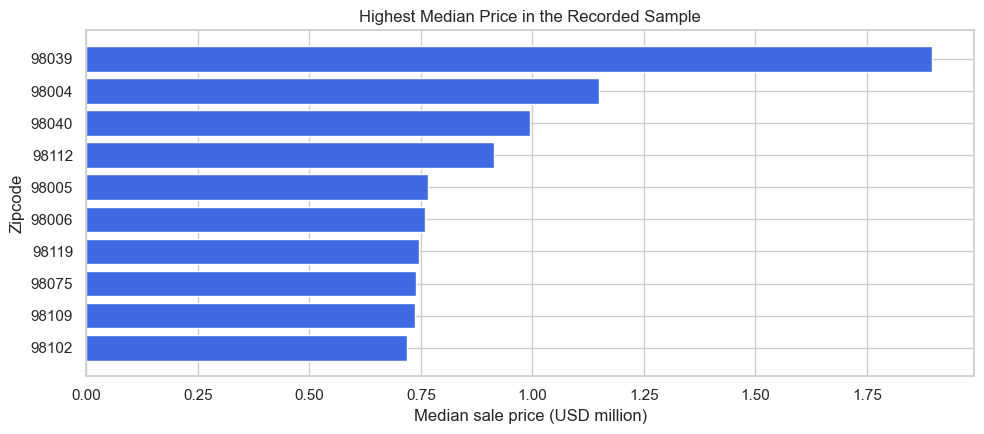

In [11]:
assert CHECKS.get('all_clean_cells_match_python') is True, 'Run previous step till PASS.'
kpi_sql = load_sql_blocks(ROOT / 'sql' / '3_business_kpis.sql')
business_results = {}

q1 = query_df(engine, kpi_sql['q1_highest_median_zipcodes'])
business_results['q1_highest_median_zipcodes'] = q1
display(q1.round(2))
fig, ax = plt.subplots(figsize = (10, 4.5))
plot_data = q1.sort_values('median_price_usd')
ax.barh(plot_data['zipcode'].astype(str), plot_data['median_price_usd'] / 1e6, color = 'royalblue')
ax.set(xlabel = 'Median sale price (USD million)', ylabel = 'Zipcode', title = 'Highest Median Price in the Recorded Sample')
fig.tight_layout()
fig.savefig(REPORT_DIR / 'q1_median_prices.png', dpi = 130, bbox_inches = 'tight')
plt.show()

**Interpretation.** ZIP code 98039 has the highest median sale price ($1,895,000; 50 transactions), followed by 98004 ($1,150,000; 317 transactions). Sample sizes and property mix differ, so these medians do not establish causal location premiums.

## 11. b. Monthly Transactions

,sale_month,sales_count,first_observed,last_observed,avg_price_usd,median_price_usd,is_boundary_month
0,2014-05-01,1768,2014-05-02,2014-05-31,548166.60,465000.0,True
1,2014-06-01,2180,2014-06-01,2014-06-30,558123.74,465000.0,False
2,2014-07-01,2211,2014-07-01,2014-07-31,544892.16,465000.0,False
3,2014-08-01,1940,2014-08-01,2014-08-31,536527.04,442100.0,False
4,2014-09-01,1774,2014-09-01,2014-09-30,529315.87,450000.0,False
5,2014-10-01,1878,2014-10-01,2014-10-31,539127.48,446900.0,False
6,2014-11-01,1411,2014-11-01,2014-11-30,522058.86,435000.0,False
7,2014-12-01,1471,2014-12-01,2014-12-31,524602.89,432500.0,False
8,2015-01-01,978,2015-01-02,2015-01-31,525963.25,438500.0,False
9,2015-02-01,1250,2015-02-01,2015-02-28,507919.60,425545.0,False


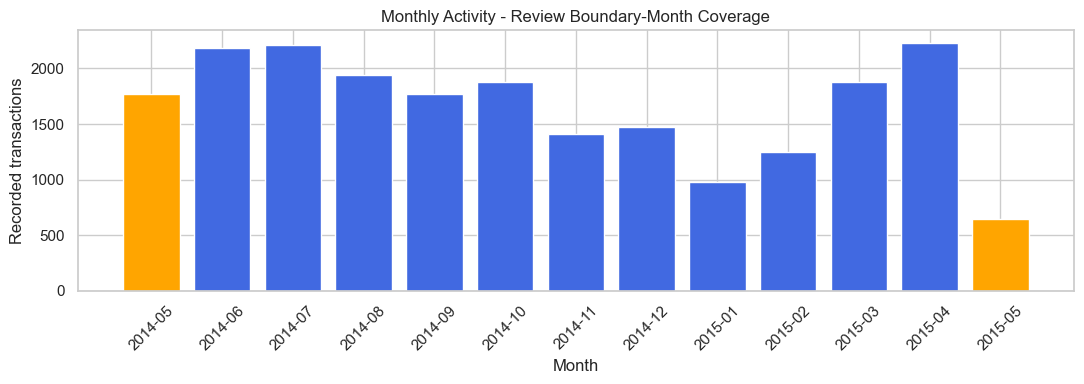

In [12]:
assert CHECKS.get('all_clean_cells_match_python') is True, 'Run previous step till PASS.'
q2 = query_df(engine, kpi_sql['q2_monthly_activity'])
business_results['q2_monthly_activity'] = q2
display(q2.round(2))
fig, ax = plt.subplots(figsize = (11, 4))
colors = np.where(q2['is_boundary_month'], 'orange', 'royalblue')
ax.bar(pd.to_datetime(q2['sale_month']).dt.strftime('%Y-%m'), q2['sales_count'], color = colors)
ax.set(xlabel = 'Month', ylabel = 'Recorded transactions', title = 'Monthly Activity - Review Boundary-Month Coverage')
ax.tick_params(axis = 'x', rotation = 45)
fig.tight_layout()
fig.savefig(REPORT_DIR / 'q2_monthly_activity.png', dpi = 130, bbox_inches = 'tight')
plt.show()

**Interpretation.** April 2015 has the highest recorded monthly count (2,231). May 2014 and May 2015 have partial coverage. Recorded transactions measure observed activity; this short series cannot establish reliable annual seasonality or changes in latent demand.

## 11. c. Areas With the Most Recorded Transactions

,zipcode,sales_count,avg_price_usd,median_price_usd
0,98103,602,585048.78,550000.0
1,98038,590,366876.07,342000.0
2,98115,583,619944.15,567000.0
3,98052,574,645244.23,615000.0
4,98117,553,576834.81,544000.0
5,98042,548,311632.11,292000.0
6,98034,545,521740.01,445950.0
7,98118,508,417645.31,367500.0
8,98023,499,286742.81,268450.0
9,98006,498,859938.55,760184.5


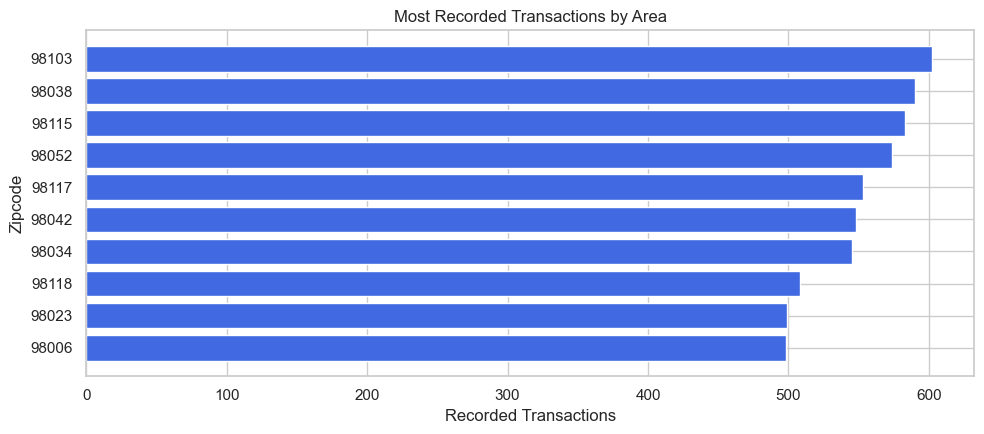

In [13]:
assert CHECKS.get('all_clean_cells_match_python') is True, 'Run previous step till PASS.'
q3 = query_df(engine, kpi_sql['q3_most_recorded_sales'])
business_results['q3_most_recorded_sales'] = q3
display(q3.round(2))
fig, ax = plt.subplots(figsize = (10, 4.5))
plot_data = q3.sort_values('sales_count')
ax.barh(plot_data['zipcode'].astype(str), plot_data['sales_count'], color = 'royalblue')
ax.set(xlabel = 'Recorded Transactions', ylabel = 'Zipcode', title = "Most Recorded Transactions by Area")
fig.tight_layout()
fig.savefig(REPORT_DIR / 'q3_sales_counts.png', dpi = 130, bbox_inches = 'tight')
plt.show()

**Interpretation.** ZIP codes 98103 and 98038 have the largest recorded transaction counts, with 602 and 590 respectively. These counts describe this dataset and are not adjusted for the local housing stock.

## 11. d. Price by Grade

,grade,sales_count,avg_price_usd,median_price_usd
0,1,1,142000.00,142000.0
1,3,3,205666.67,262000.0
2,4,29,214381.03,205000.0
3,5,242,248523.97,228700.0
4,6,2038,301916.57,275276.5
5,7,8981,402593.32,375000.0
6,8,6068,542895.50,510000.0
7,9,2615,773738.22,720000.0
8,10,1134,1072347.47,914327.0
9,11,399,1497792.38,1280000.0


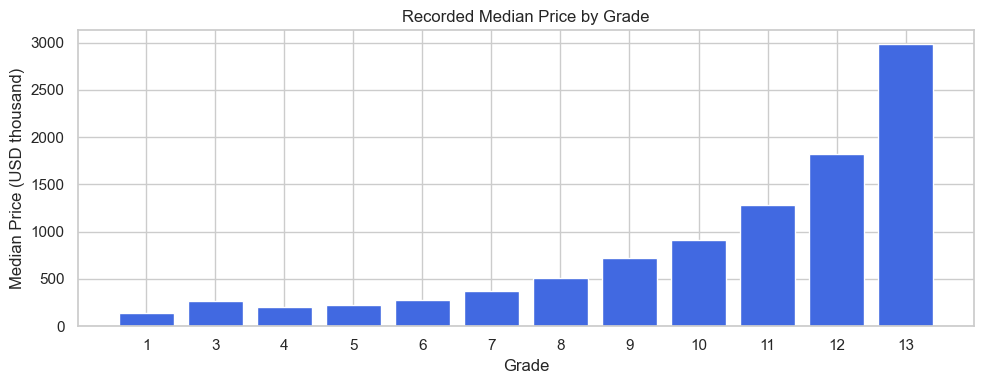

In [14]:
assert CHECKS.get('all_clean_cells_match_python') is True, 'Run previous step till PASS.'
q4 = query_df(engine, kpi_sql['q4_price_by_grade'])
business_results['q4_price_by_grade'] = q4
display(q4.round(2))
fig, ax = plt.subplots(figsize= (10, 4))
ax.bar(q4['grade'].astype(str), q4['median_price_usd'] / 1e3, color = 'royalblue')
ax.set(xlabel = 'Grade', ylabel = 'Median Price (USD thousand)', title = 'Recorded Median Price by Grade')
fig.tight_layout()
plt.savefig(REPORT_DIR / 'q4_price_by_grade.png', dpi = 130, bbox_inches = 'tight')
plt.show()

**Interpretation.** Median prices rise from $375,000 at grade 7 to $510,000 at grade 8 and $720,000 at grade 9. The association does not isolate a causal effect of grade because location and other property attributes also differ.

## 11. e. Waterfront Comparison

,waterfront,sales_count,avg_price_usd,median_price_usd
0,0,21450,531653.41,450000.0
1,1,163,1662524.18,1400000.0


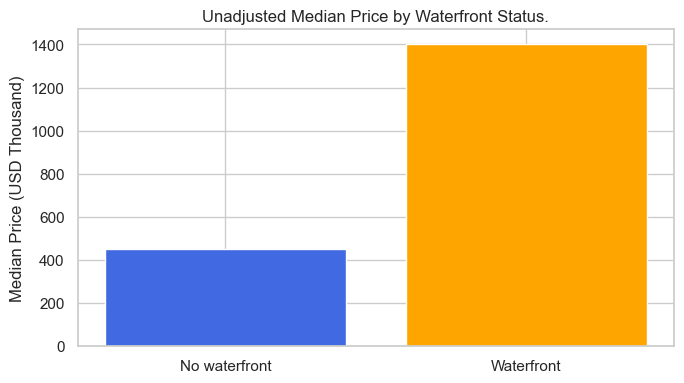

In [15]:
assert CHECKS.get('all_clean_cells_match_python') is True, 'Run previous step till PASS.'
q5 = query_df(engine, kpi_sql['q5_waterfront_comparison'])
business_results['q5_waterfront_comparison'] = q5
display(q5.round(2))
fig, ax = plt.subplots(figsize = (7, 4))
labels = q5['waterfront'].map({0: 'No waterfront', 1: 'Waterfront'})
ax.bar(labels, q5['median_price_usd'] / 1e3, color = ['royalblue', 'orange'])
ax.set(ylabel = 'Median Price (USD Thousand)', title = 'Unadjusted Median Price by Waterfront Status.')
fig.tight_layout()
fig.savefig(REPORT_DIR / 'q5_waterfront_prices.png', dpi = 130, bbox_inches = 'tight')
plt.show()

**Interpretation.** Waterfront properties have a median price of $1,400,000 across 163 transactions; non-waterfront properties have a median of $450,000 across 21,450 transactions. The groups differ in size and characteristics, so the price gap is descriptive.

## 12. Validate All Aggregates and Save Results

In [16]:
CHECKS.pop('analytic_views_match_python', None)
assert CHECKS.get('all_clean_cells_match_python') is True, 'Run previous step till PASS.'
def verify_group_view(table_name, key):
    allowed = {'sales_by_zipcode', 'sales_by_grade', 'sales_by_waterfront'}
    assert table_name in allowed
    sql_group = query_df(engine, f'SELECT * FROM analytics.{table_name} ORDER BY {key}')
    py_group = python_normalized.groupby(key).agg(
        sales_count = ('price', 'size'), avg_price_usd = ('price', 'mean'), median_price_usd = ('price', 'median')
    ).reset_index()
    if key == 'zipcode':
        sql_group[key] = sql_group[key].astype('string')
        py_group[key] = py_group[key].astype('string')
    else:
        sql_group[key] = sql_group[key].astype('int64')
        py_group[key] = py_group[key].astype('int64')
    columns = [key, 'sales_count', 'avg_price_usd', 'median_price_usd']
    left = sql_group[columns].sort_values(key).reset_index(drop = True)
    right = py_group[columns].sort_values(key).reset_index(drop = True)
    pd.testing.assert_frame_equal(left, right, check_dtype = False, check_exact = False, rtol = 1e-12, atol = 1e-8)
    assert int(sql_group['sales_count'].sum()) == manifest['row_count']
    
verify_group_view('sales_by_zipcode', 'zipcode')
verify_group_view('sales_by_grade', 'grade')
verify_group_view('sales_by_waterfront', 'waterfront')

py_monthly = python_normalized.assign(sale_month = python_normalized['date'].dt.to_period('M').dt.to_timestamp()).groupby('sale_month').agg(
    sales_count = ('price', 'size'), first_observed = ('date', 'min'), last_observed = ('date', 'max'),
    avg_price_usd = ('price', 'mean'), median_price_usd = ('price', 'median')
).reset_index()
sql_monthly = q2.copy()
for field in ['sale_month', 'first_observed', 'last_observed']:
    sql_monthly[field] = pd.to_datetime(sql_monthly[field])
columns = ['sale_month', 'sales_count', 'first_observed', 'last_observed', 'avg_price_usd', 'median_price_usd']
pd.testing.assert_frame_equal(sql_monthly[columns].reset_index(drop = True), py_monthly[columns].reset_index(drop = True),
                              check_dtype = False, check_exact = False, rtol = 1e-12, atol = 1e-8)
boundary_expected =  sql_monthly['sale_month'].isin([sql_monthly['sale_month'].min(), sql_monthly['sale_month'].max()])
assert sql_monthly['is_boundary_month'].astype(bool).equals(boundary_expected)
assert int(sql_monthly['sales_count'].sum()) == manifest['row_count']

for name, frame in business_results.items():
    frame.to_csv(REPORT_DIR / f'{name}.csv', index = False)
CHECKS['analytic_views_match_python'] = True
print('PASS: all four analytic views agree with the Python reference; five query outputs saved.')

PASS: all four analytic views agree with the Python reference; five query outputs saved.


## 13. Save the Validation Report

In [17]:
required_checks = [
    'reference_source_match', 
    'database_connection', 
    'schema_verified',
    'raw_cells_equal_csv',
    'raw_quality_passed',
    'duplicate_checks_match_python',
    'domain_checks_match_python',
    'clean_summary_matches',
    'all_clean_cells_match_python',
    'analytic_views_match_python'
]

assert all(CHECKS.get(name) is True for name in required_checks), 'Some stages were not verified in this run'
run_report = {
    'status': 'passed_programmatic_checks',
    'database': connection_info.loc[0, 'database_name'],
    'postgresql_version': str(connection_info.loc[0, 'server_version']),
    'source_sha256': source_digest,
    'rows_compared': len(sql_normalized),
    'clean_columns_compared': len(clean_columns),
    'checks': CHECKS,
    'sql_sha256': {
        path.name: hashlib.sha256(path.read_bytes()).hexdigest()
        for path in sorted((ROOT / 'sql').glob('*.sql'))
    },
    'python': sys.version.split()[0],
    'packages': {name: version(name) for name in ['pandas', 'numpy', 'SQLAlchemy', 'psycopg', 'python-dotenv']},
    'business_interpretations': 'Review separately in docs/business_insights.md'
}
report_path = REPORT_DIR / 'validation_report.json'
report_path.write_text(json.dumps(run_report, indent = 2), encoding = 'utf-8')
print(json.dumps(run_report, indent = 2))
engine.dispose()

{
  "status": "passed_programmatic_checks",
  "database": "property_analytics_database",
  "postgresql_version": "18.6",
  "source_sha256": "02d5580da2ef7f0dd69effdf68f59a5a6788fe4f55533dab3e9e035d4bd4586e",
  "rows_compared": 21613,
  "clean_columns_compared": 28,
  "checks": {
    "reference_source_match": true,
    "database_connection": true,
    "schema_verified": true,
    "raw_cells_equal_csv": true,
    "raw_quality_passed": true,
    "duplicate_checks_match_python": true,
    "domain_checks_match_python": true,
    "clean_summary_matches": true,
    "all_clean_cells_match_python": true,
    "analytic_views_match_python": true
  },
  "sql_sha256": {
    "0_schema.sql": "82dfa42c04d2c717660a1f16a23bb5e60da1ab1c27383162b062a9238d62564a",
    "1_quality_checks.sql": "07807aefdb3bc295302284c695d7fdfd2c47a63780448614c7b579735a1b0c77",
    "2_clean_view.sql": "3f4a1c8c76c318aef8ca68d336c7193c5a62518d2ff464cba85f8cc8fe08314d",
    "3_business_kpis.sql": "bd8705904138caef253e2276f58af1